# Affordable Housing Distribution by Community Area

This notebook summarizes the saved September 2026 affordable housing dataset by listed community area and property type. It finishes the October 1 analysis checkpoint.

The counts describe documented City-supported developments. They do not show current vacancies or whether someone can access housing right now. Missing unit counts stay missing.

Notebook 03 applies reviewed category corrections recorded in `docs/HOUSING_CATEGORY_CORRECTIONS.csv`. Seven other records have coordinate disagreements listed in `docs/GEOGRAPHY_REVIEW_FLAGS.csv`. Their listed areas are retained pending the later geography review. These are preliminary area totals.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

current_folder = Path.cwd()
project_root = current_folder.parent if current_folder.name == "notebooks" else current_folder
clean_path = project_root / "data" / "processed" / "affordable_housing_cleaned.csv"
assert clean_path.exists(), "Run Notebook 03 first."
housing = pd.read_csv(clean_path)
housing["units"] = pd.to_numeric(housing["units"], errors="raise")
housing["units_missing"] = housing["units"].isna()
assert not housing.empty
assert housing["units"].dropna().gt(0).all()
assert housing["community_area_number"].notna().all()
assert housing["community_area"].notna().all()
assert housing.groupby("community_area_number")["community_area"].nunique().le(1).all()
assert housing.groupby("community_area")["community_area_number"].nunique().le(1).all()
assert not housing["property_type"].isin(["Mutifamily", "Multfamily"]).any()
print("Development records:", len(housing))
print("Records with missing units:", int(housing["units_missing"].sum()))

Development records: 598
Records with missing units: 1


In [2]:
community_summary = (
    housing.groupby(
        ["community_area_number", "community_area"],
        dropna=False,
    )
    .agg(
        development_records=("property_name", "size"),
        known_unit_records=("units", "count"),
        documented_units_known=(
            "units",
            lambda values: values.sum(min_count=1),
        ),
        missing_unit_records=("units_missing", "sum"),
        median_units_per_development=("units", "median"),
    )
    .reset_index()
)

community_summary["unit_reporting_rate"] = (
    community_summary["known_unit_records"]
    / community_summary["development_records"]
    * 100
).round(1)

community_summary = community_summary.sort_values(
    "documented_units_known",
    ascending=False,
)

In [3]:
property_type_summary = (
    housing.groupby(
        "property_type",
        dropna=False,
    )
    .agg(
        development_records=("property_name", "size"),
        known_unit_records=("units", "count"),
        documented_units_known=(
            "units",
            lambda values: values.sum(min_count=1),
        ),
        missing_unit_records=("units_missing", "sum"),
        median_units_per_development=("units", "median"),
    )
    .reset_index()
)

property_type_summary["unit_reporting_rate"] = (
    property_type_summary["known_unit_records"]
    / property_type_summary["development_records"]
    * 100
).round(1)

property_type_summary = property_type_summary.sort_values(
    "documented_units_known",
    ascending=False,
)

In [4]:
known_units_total = housing["units"].sum(min_count=1)
assert known_units_total > 0
community_summary["share_of_known_units_percent"] = (
    community_summary["documented_units_known"] / known_units_total * 100
)
community_summary["known_unit_rank"] = (
    community_summary["documented_units_known"]
    .rank(method="min", ascending=False).astype("Int64")
)
community_summary = community_summary.sort_values(
    ["known_unit_rank", "community_area"]
).reset_index(drop=True)
property_type_summary = property_type_summary.sort_values(
    ["documented_units_known", "property_type"], ascending=[False, True]
).reset_index(drop=True)

for summary in [community_summary, property_type_summary]:
    assert summary["development_records"].sum() == len(housing)
    assert summary["known_unit_records"].sum() == housing["units"].notna().sum()
    assert summary["missing_unit_records"].sum() == housing["units_missing"].sum()
    assert summary["documented_units_known"].sum() == known_units_total
    assert (summary["known_unit_records"] + summary["missing_unit_records"]).equals(
        summary["development_records"]
    )
assert community_summary["community_area_number"].is_unique
assert property_type_summary["property_type"].is_unique
assert abs(community_summary["share_of_known_units_percent"].sum() - 100) < 1e-8
print("Total known documented units:", int(known_units_total))
print("Community area groups:", len(community_summary))
print("Property type groups:", len(property_type_summary))
print("Percentage total:", round(community_summary["share_of_known_units_percent"].sum(), 2))
display(community_summary.head(15))
display(property_type_summary)

Total known documented units: 29550
Community area groups: 66
Property type groups: 28
Percentage total: 100.0


,community_area_number,community_area,development_records,known_unit_records,documented_units_known,missing_unit_records,median_units_per_development,unit_reporting_rate,share_of_known_units_percent,known_unit_rank
0,38,Grand Boulevard,30,30,2406.0,0,69.0,100.0,8.142132,1
1,28,Near West Side,35,34,1958.0,1,52.0,97.1,6.626058,2
2,33,Near South Side,12,12,1473.0,0,139.0,100.0,4.984772,3
3,3,Uptown,39,39,1432.0,0,12.0,100.0,4.846024,4
4,8,Near North Side,24,24,1312.0,0,40.5,100.0,4.439932,5
5,27,East Garfield Park,14,14,1205.0,0,78.0,100.0,4.077834,6
6,29,North Lawndale,35,35,1193.0,0,26.0,100.0,4.037225,7
7,1,Rogers Park,10,10,1178.0,0,57.0,100.0,3.986464,8
8,23,Humboldt Park,48,48,1139.0,0,8.5,100.0,3.854484,9
9,36,Oakland,18,18,1063.0,0,6.0,100.0,3.597293,10


,property_type,development_records,known_unit_records,documented_units_known,missing_unit_records,median_units_per_development,unit_reporting_rate
0,Multifamily,263,263,13103.0,0,29.0,100.0
1,Senior,106,106,9809.0,0,85.0,100.0
2,Supportive Housing,27,27,2113.0,0,69.0,100.0
3,ARO,156,155,1727.0,1,5.0,99.4
4,SRO,3,3,445.0,0,148.0,100.0
5,Senior HUD 202,6,6,375.0,0,60.0,100.0
6,Supportive,5,5,351.0,0,70.0,100.0
7,Senior Supportive Living,3,3,287.0,0,97.0,100.0
8,Supportive/Veterans,4,4,225.0,0,52.0,100.0
9,People with Disabilities,5,5,198.0,0,25.0,100.0


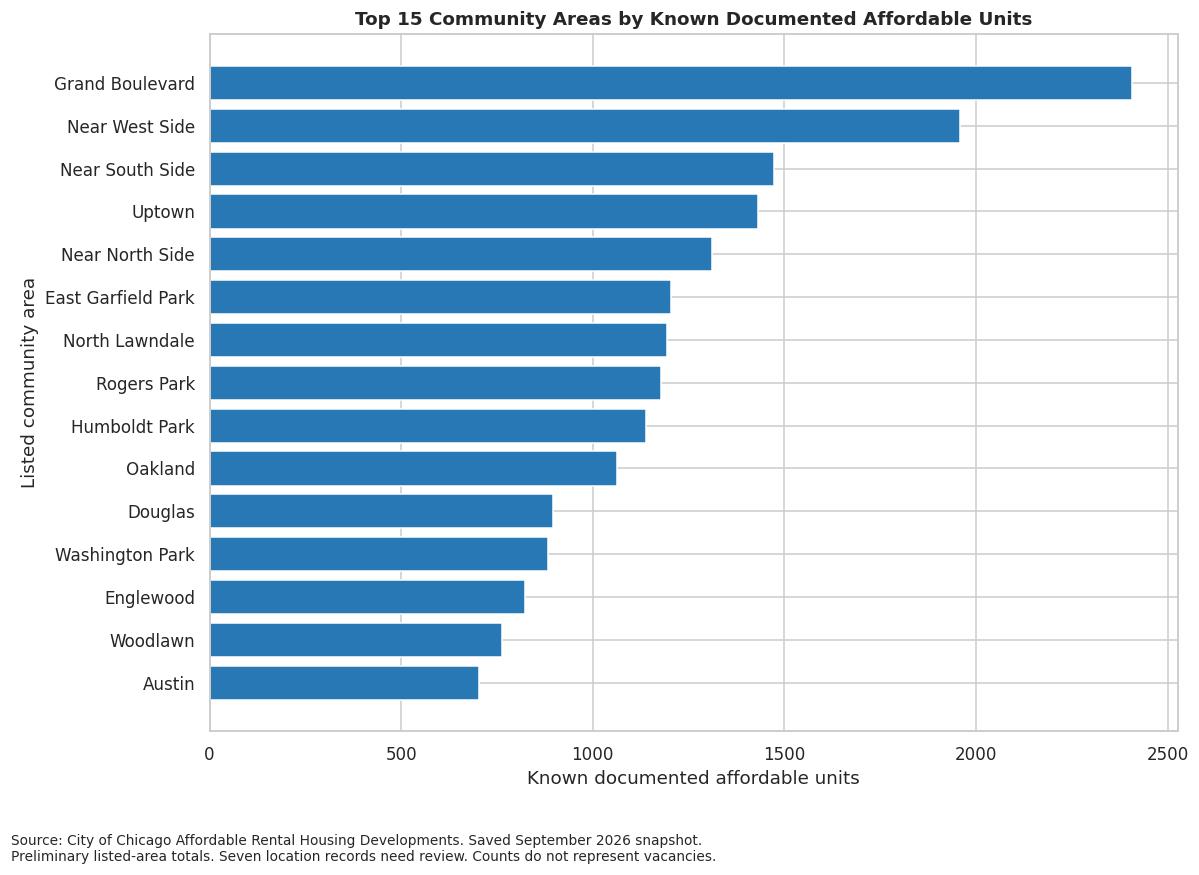

In [5]:
plot_data = community_summary.head(15).sort_values(
    "documented_units_known", ascending=True
)
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(11, 8))
ax.barh(plot_data["community_area"], plot_data["documented_units_known"], color="#2878B5")
ax.set_title("Top 15 Community Areas by Known Documented Affordable Units", weight="bold")
ax.set_xlabel("Known documented affordable units")
ax.set_ylabel("Listed community area")
fig.text(0.01, 0.01,
    "Source: City of Chicago Affordable Rental Housing Developments. Saved September 2026 snapshot.\n"
    "Preliminary listed-area totals. Seven location records need review. Counts do not represent vacancies.",
    fontsize=9)
fig.tight_layout(rect=(0, 0.07, 1, 1))
figure_path = project_root / "reports" / "figures" / "top_community_areas_affordable_units.png"
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path, dpi=200, bbox_inches="tight")
plt.show()

In [6]:
processed_folder = project_root / "data" / "processed"
processed_folder.mkdir(parents=True, exist_ok=True)
community_output_path = processed_folder / "affordable_housing_by_community_area.csv"
property_type_output_path = processed_folder / "affordable_housing_by_property_type.csv"
community_summary.to_csv(community_output_path, index=False)
property_type_summary.to_csv(property_type_output_path, index=False)
saved_community = pd.read_csv(community_output_path)
saved_property_types = pd.read_csv(property_type_output_path)
pd.testing.assert_frame_equal(
    saved_community, community_summary, check_dtype=False
)
pd.testing.assert_frame_equal(
    saved_property_types, property_type_summary, check_dtype=False
)
print("Both summary files saved and matched after reopening.")

Both summary files saved and matched after reopening.


## Initial Finding

Grand Boulevard has the highest known unit count in this dataset. It has **2,406 known documented units across 30 development records**. That is about **8.14% of the 29,550 known units** in the saved dataset.

The summary includes all **598 development records**. One record has no unit count. Its missing value was kept instead of being changed to zero.

The corrected summary has **66 listed community areas and 28 property types**. An area missing from this inventory should not automatically be treated as having no affordable housing.

These are preliminary totals. Seven records still need a geography review because their coordinates disagree with their listed areas. The counts also do not show vacancies or whether supply meets local need. Housing need and demographic data are needed before making allocation recommendations.

In [7]:
assert figure_path.exists() and figure_path.stat().st_size > 0
assert community_output_path.exists() and property_type_output_path.exists()
review_flags = pd.read_csv(project_root / "docs" / "GEOGRAPHY_REVIEW_FLAGS.csv")
print("Geography records reserved for later review:", len(review_flags))
print("All Notebook 04 deliverables passed verification.")

Geography records reserved for later review: 7
All Notebook 04 deliverables passed verification.
